# Phase 2 - Positions study

This notebook checks whether the relative positions of the dependency graph (level 3) can be measured from the labels of Phase 1.

## Section 1 - Purpose and questions

The dependency graph describes the correct assembly in levels. Level 1 lists the parts, level 2 says on which part each one is mounted, level 3 adds optional relative positions: above, right of, left of.

Level 3 is needed to see placement errors, such as the nose in the place of the eyes. Without it, a nose mounted on the body looks correct wherever it is.

The positions are not computed by a model. C-RADIO only labels each patch. The relation is computed from the centre of each part region on the 64 x 64 grid: "A above B" means that the centre of A is higher in the image than the centre of B.

The video comes from the headset (Meta Quest 3), so the camera moves with the head. The method may not hold: a tilted head, a view from above, wrong regions and unknown front and back can all turn a correct relation into a violated one.

This study measures the method on assembly_2, the development video. The assembly in assembly_2 is always correct, so every violated relation is a false alarm.

Three questions are asked. How often is a correct relation found violated? On how many frames can each relation be checked? How far apart are the two centres, in patches?

The vertical relations are studied first, because they do not need to know where the front of the figure is. The relations on the sides come second.

This is an exploration, not the decision. No threshold is fixed here. If false alarms are frequent, level 3 is removed and the framework works at level 2. If they are rare, level 3 is kept and its rule is fixed later with the procedure of the evaluation plan.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

Jones, Hager, Khudanpur, Toward Computer Vision Systems That Understand Real-World Assembly Processes, WACV 2019: the assembly state as a graph of parts and connections, with the relative pose on each connection, evaluated at levels of spatial detail.

Kamath, Hessel, Chang, What's "up" with vision-language models? Investigating their struggle with spatial reasoning, EMNLP 2023: vision-language models fail on simple spatial relations, so the relations are computed by code.

configs/dependency_graph.json: the positions, marked "to be validated".

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

All paths and settings in one place. The settings are those of the pipeline (phase_1_perception.ipynb, Section 2.5), so that A is applied exactly as in Phase 1.

A is not rebuilt here. It is loaded from the prototypes saved by the pipeline (patch_prototypes.npz), as in the study of the support set by condensation.

The labels of assembly_2 come from the support-set study on V2 (key "current", which is A). Section 3 checks them on a few frames with the final code before they are used.

In [1]:
# 2.1 Imports, paths and shared module
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import cv2
from PIL import Image
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

from perception.classes import CLASS_NAMES
from perception.features import FeatureExtractor
from perception.prototypes import load_patch_prototypes, class_similarities_gpu, assign_labels

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
VIDEO_PATH = PROJECT_ROOT / "data" / "raw_videos" / "assembly_2.mp4"
EVENTS_PATH = PROJECT_ROOT / "configs" / "assembly_2_events.json"
GRAPH_PATH = PROJECT_ROOT / "configs" / "dependency_graph.json"
PROTOTYPES_PATH = PROJECT_ROOT / "outputs" / "phase_1_perception" / "patch_prototypes.npz"   # support set A, read only
LABELS_PATH = PROJECT_ROOT / "outputs" / "phase_1_support_set_v2_study" / "assembly_2_labels_current_protected.npz"  # read only
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_2_positions_study"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "VIDEO_PATH": VIDEO_PATH, "EVENTS_PATH": EVENTS_PATH,
                   "GRAPH_PATH": GRAPH_PATH, "PROTOTYPES_PATH": PROTOTYPES_PATH, "LABELS_PATH": LABELS_PATH}.items():
    print(f"[{'OK' if path.exists() else 'MISSING'}] {name}: {path.relative_to(PROJECT_ROOT)}")

[OK] MODEL_DIR: models\c_radio_weights
[OK] VIDEO_PATH: data\raw_videos\assembly_2.mp4
[OK] EVENTS_PATH: configs\assembly_2_events.json
[OK] GRAPH_PATH: configs\dependency_graph.json
[OK] PROTOTYPES_PATH: outputs\phase_1_perception\patch_prototypes.npz
[OK] LABELS_PATH: outputs\phase_1_support_set_v2_study\assembly_2_labels_current_protected.npz


In [2]:
# 2.2 Settings
# Values of the pipeline (phase_1_perception.ipynb, Section 2.5); the input size is the one the extractor gives for these videos.
DEVICE, DTYPE = "cuda", torch.bfloat16
INPUT_SIZE, PATCH_SIZE = (1024, 1024), 16
MARGIN = 0.0                    # background margin of V2 (margin study, Section 9)
N_CHECK_FRAMES = 10             # frames of assembly_2 recomputed with the final code (Section 3)

Observation 2: The six paths exist: the C-RADIO weights, the video and the event log of assembly_2, the dependency graph, the prototypes of A and the saved labels of assembly_2. The settings are those of the pipeline: bfloat16 on the GPU, input 1024 x 1024, patches of 16 pixels, margin 0.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 2:

phase_1_perception.ipynb, Section 2.5: the settings of the pipeline; Section 6.4: the prototypes of A saved in patch_prototypes.npz.

phase_1_support_set_v2_study.ipynb, Section 10.1: the labels of assembly_2 with the support sets "current" (A) and "protected".

phase_1_support_set_hart.ipynb, Section 2.1: A loaded from the saved prototypes, read only.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - The labels of assembly_2

Phase 2 works on the labels of every frame, not on the video. For assembly_2 they were saved by the support-set study on V2 (version v1.7), with the support set "current", which is A: same 39,125 prototypes, margin 0, mIoU 0.779 in validation.

The code changed between v1.7 and the final pipeline. The labels are therefore checked before use: A is applied again, with the final code, to a few frames of assembly_2, and the result is compared patch by patch with the saved labels.

The frames are fixed by a rule, not chosen by looking: 10 frames evenly spaced over the whole video. If no patch differs, the saved labels are used. If any patch differs, the labels of the whole video are computed again.

In [3]:
# 3.1 Support set A (saved prototypes of the pipeline) and the saved labels of assembly_2
from perception.labels import sequence_of

saved = load_patch_prototypes(PROTOTYPES_PATH)
A_VECTORS, A_OWNERS = saved["prototypes"], saved["owners"]
reference_sequences = {sequence_of(r["frame"]) for r in saved["metadata"]["reference_frames"]}
assert saved["class_names"] == CLASS_NAMES, "Class order in the file must match CLASS_NAMES"
assert not reference_sequences & {"assembly_1", "assembly_2"}, "A must not use the videos of Phase 2"
A_GPU = tuple(torch.as_tensor(x, device=DEVICE) for x in (A_VECTORS, A_OWNERS))
print(f"A: {len(A_VECTORS)} prototypes from {len(reference_sequences)} reference sequences: {sorted(reference_sequences)}")

stored = np.load(LABELS_PATH)
LABELS = stored["current"]
assert [str(c) for c in stored["class_names"]] == CLASS_NAMES, "Class order of the saved labels must match CLASS_NAMES"

cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS, N_FRAMES = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
GRID = (INPUT_SIZE[0] // PATCH_SIZE, INPUT_SIZE[1] // PATCH_SIZE)
assert LABELS.shape == (N_FRAMES, *GRID), f"Saved labels {LABELS.shape} do not match the video"
print(f"Saved labels: {LABELS.shape[0]} frames, grid {GRID}; video: {N_FRAMES} frames at {FPS:.3f} fps "
      f"(saved fps {float(stored['fps']):.3f})")

A: 39125 prototypes from 6 reference sequences: ['2_disassembled_caos', '3_disassembled_ordered', '4_partially_assembled', '5_assembled', 'Take_3_1_Base', 'caos']
Saved labels: 2444 frames, grid (64, 64); video: 2444 frames at 29.996 fps (saved fps 29.996)


In [4]:
# 3.2 A applied again, with the final code, to 10 frames evenly spaced over assembly_2
CHECK_FRAMES = np.linspace(0, N_FRAMES - 1, N_CHECK_FRAMES).round().astype(int)

extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
assert extractor.patch_size == PATCH_SIZE

recomputed = {}
start = time.time()
cap = cv2.VideoCapture(str(VIDEO_PATH))
for f in range(N_FRAMES):                       # frames are read in order: seeking can land on the wrong frame
    ok, frame_bgr = cap.read()
    if not ok:
        break
    if f in CHECK_FRAMES:
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        features, size = extractor.extract(Image.fromarray(frame_rgb))
        assert tuple(size) == INPUT_SIZE
        recomputed[f] = assign_labels(class_similarities_gpu(features, *A_GPU), MARGIN)
    if f >= CHECK_FRAMES[-1]:
        break
cap.release()
print(f"Frames checked: {CHECK_FRAMES.tolist()}")
print(f"{len(recomputed)} frames recomputed in {time.time() - start:.0f} s")

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Frames checked: [0, 271, 543, 814, 1086, 1357, 1629, 1900, 2172, 2443]
10 frames recomputed in 11 s


In [5]:
# 3.3 Recomputed labels against the saved labels, patch by patch
rows = []
for f, labels in recomputed.items():
    different = labels.astype(np.int64) != LABELS[f].astype(np.int64)
    rows.append({"frame": f, "time (s)": round(f / FPS, 1),
                 "patches compared": different.size, "patches different": int(different.sum())})
check = pd.DataFrame(rows).set_index("frame")
display(check)

TOTAL_DIFFERENT = int(check["patches different"].sum())
print(f"Patches different over {len(check)} frames: {TOTAL_DIFFERENT} of {int(check['patches compared'].sum())}")
print("Saved labels confirmed: they are used." if TOTAL_DIFFERENT == 0
      else "Saved labels differ: the labels of the whole video must be computed again.")

,time (s),patches compared,patches different
frame,,,
0,0.0,4096,0
271,9.0,4096,0
543,18.1,4096,0
814,27.1,4096,0
1086,36.2,4096,0
1357,45.2,4096,0
1629,54.3,4096,0
1900,63.3,4096,0
2172,72.4,4096,0


Patches different over 10 frames: 0 of 40960
Saved labels confirmed: they are used.


Observation 3: A has 39,125 prototypes from 6 reference sequences, none of them assembly_1 or assembly_2. The saved labels have 2444 frames on a 64 x 64 grid, as many as the frames of the video (29.996 fps).

A applied again with the final code to 10 frames evenly spaced over the video (frames 0 to 2443, one every about 9 s) gives the saved labels exactly: 0 different patches out of 40,960. The saved labels of assembly_2 are A and are used in the rest of Phase 2. Recomputing the 10 frames takes 12 s.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3:

phase_1_support_set_v2_study.ipynb, Section 10.1: the saved labels of assembly_2; Observations 4.2 and 8.1: the support set "current" has 39,125 prototypes at margin 0.

phase_1_support_set_hart.ipynb, Section 3.3: the same kind of regression check of A, on assembly_1, against the test of Phase 1.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Vertical relations

The vertical relations of the graph are studied first: body above base, hat above eyes, eyes above nose, moustache above mouth, ears above arm_1, ears above arm_2. They do not need to know where the front of the figure is.

A relation must hold only when both parts are mounted and settled. It is checked from the frame when the hands leave the second of the two parts (hands_off in the event log) to the end of the video. Before hands_off a part can still be pushed and turned, as arm_2 in assembly_2. After it, every frame where both parts are seen is counted, also when a hand is on the figure.

Each part is the largest region of its class, made of patches that touch also on the diagonal, because the arms are thin and oblique. The two ears are the two largest regions of their class. Smaller regions of the same class are ignored. How often a class has more than one region is counted, to know how often this choice matters.

The centre of a region is the mean row of its patches, with row 0 at the top. "A above B" holds when the row of A is smaller than the row of B. There is no margin: any inversion is a violation. The distance between the two centres is kept, to know later how much margin would be needed. For the ears, a relation is violated when at least one visible ear is below the arm.

The frames are also split by whether a hand touches one of the two parts. This tells whether the false alarms come from the hands.

In [6]:
# 4.1 From when each vertical relation must hold: hands_off of the second part (event log)
EVENTS = json.load(open(EVENTS_PATH))["events"]
GRAPH = json.load(open(GRAPH_PATH))

SETTLED = {}                                    # frame from which every copy of a part is mounted and settled
for e in EVENTS:
    assert e["hands_off"] is not None, f"{e['piece']} has no hands_off"
    SETTLED[e["piece"]] = max(SETTLED.get(e["piece"], -1), e["hands_off"])

VERTICAL = [(a, b) for a, relation, b in GRAPH["positions"] if relation == "above"]

rows = []
for a, b in VERTICAL:
    start = max(SETTLED[a], SETTLED[b])
    rows.append({"relation": f"{a} above {b}", "settled A": SETTLED[a], "settled B": SETTLED[b],
                 "from frame": start, "from (s)": round(start / FPS, 1), "frames to check": N_FRAMES - start})
WINDOWS = pd.DataFrame(rows).set_index("relation")
display(WINDOWS)

,settled A,settled B,from frame,from (s),frames to check
relation,,,,,
body above base,425,168,425,14.2,2019
hat above eyes,2250,1328,2250,75.0,194
eyes above nose,1328,1030,1328,44.3,1116
moustache above mouth,1030,640,1030,34.3,1414
ear above arm_1,1652,1875,1875,62.5,569
ear above arm_2,1652,2005,2005,66.8,439


Observation 4.1: The six vertical relations must hold from the hands_off of their second part to the end of the video. Body above base has the longest window, 2019 frames from 14.2 s. Hat above eyes has the shortest, 194 frames from 75.0 s, because the hat is mounted last. The other four have between 439 and 1414 frames.

In [7]:
# 4.2 Regions of each part in every frame: the largest one(s), their centre, and whether a hand touches them
HAND_ID = CLASS_NAMES.index("hand")
PARTS = sorted({p for pair in VERTICAL for p in pair})
COPIES = {p: GRAPH["parts"][p]["count"] for p in PARTS}       # 2 for ear, 1 for the others
KERNEL = np.ones((3, 3), np.uint8)                            # one patch around a region, also on the diagonal


def part_regions(labels, class_id, copies, hand_mask):
    """Regions of one class (patches touching also on the diagonal), largest first; keeps `copies` of them."""
    mask = (labels == class_id).astype(np.uint8)
    n, components, stats, centres = cv2.connectedComponentsWithStats(mask, connectivity=8)
    regions = []
    for k in range(1, n):                                     # component 0 is everything else
        touched = cv2.dilate((components == k).astype(np.uint8), KERNEL) & hand_mask
        regions.append({"size": int(stats[k, cv2.CC_STAT_AREA]),
                         "row": float(centres[k][1]), "col": float(centres[k][0]),
                         "hand": bool(touched.any())})
    regions.sort(key=lambda r: -r["size"])
    return n - 1, regions[:copies]


REGIONS = {p: [] for p in PARTS}                              # REGIONS[part][frame] = kept regions
N_REGIONS = {p: np.zeros(N_FRAMES, dtype=int) for p in PARTS} # all regions of the class in the frame
start = time.time()
for f in range(N_FRAMES):
    hand_mask = (LABELS[f] == HAND_ID).astype(np.uint8)
    for p in PARTS:
        N_REGIONS[p][f], kept = part_regions(LABELS[f], CLASS_NAMES.index(p), COPIES[p], hand_mask)
        REGIONS[p].append(kept)
print(f"Regions of {len(PARTS)} parts in {N_FRAMES} frames, {time.time() - start:.1f} s")

rows = []
for p in PARTS:
    frames = range(SETTLED[p], N_FRAMES)                      # from when the part is mounted and settled
    seen = [f for f in frames if len(REGIONS[p][f]) == COPIES[p]]
    rows.append({"part": p, "copies": COPIES[p], "frames after settled": len(frames),
                 "all copies seen": len(seen),
                 "more regions than copies": int(sum(N_REGIONS[p][f] > COPIES[p] for f in frames)),
                 "median size kept (patches)": float(np.median([r["size"] for f in seen for r in REGIONS[p][f]])) if seen else None})
display(pd.DataFrame(rows).set_index("part"))

Regions of 10 parts in 2444 frames, 1.8 s


,copies,frames after settled,all copies seen,more regions than copies,median size kept (patches)
part,,,,,
arm_1,1,569,551,45,8.0
arm_2,1,439,434,49,7.0
base,1,2276,2276,1076,29.0
body,1,2019,2019,1295,39.0
ear,2,792,768,47,8.0
eyes,1,1116,1111,2,10.0
hat,1,194,194,14,22.0
moustache,1,1414,1298,681,6.0
mouth,1,1804,1718,23,3.0


Observation 4.2: Computing the regions of the 10 parts in the 2444 frames takes 1.9 s. After being settled, almost every part is seen in almost every frame: arm_1 in 551 of 569 frames, both ears in 768 of 792, the mouth in 1718 of 1804, body and base always.

The class has more regions than copies rarely for the eyes (2 of 1116 frames), the mouth (23 of 1804) and the arms (45 of 569 and 49 of 439). It happens often for the body (1295 of 2019), the base (1076 of 2276), the moustache (681 of 1414) and the nose (491 of 1414). For these parts the choice of the largest region is often used.

Hypothesis: the body is cut into several regions by the parts mounted on its face, and nose and moustache, being attached, split each other. The median size of the region kept is 3 patches for the mouth and 39 for the body.

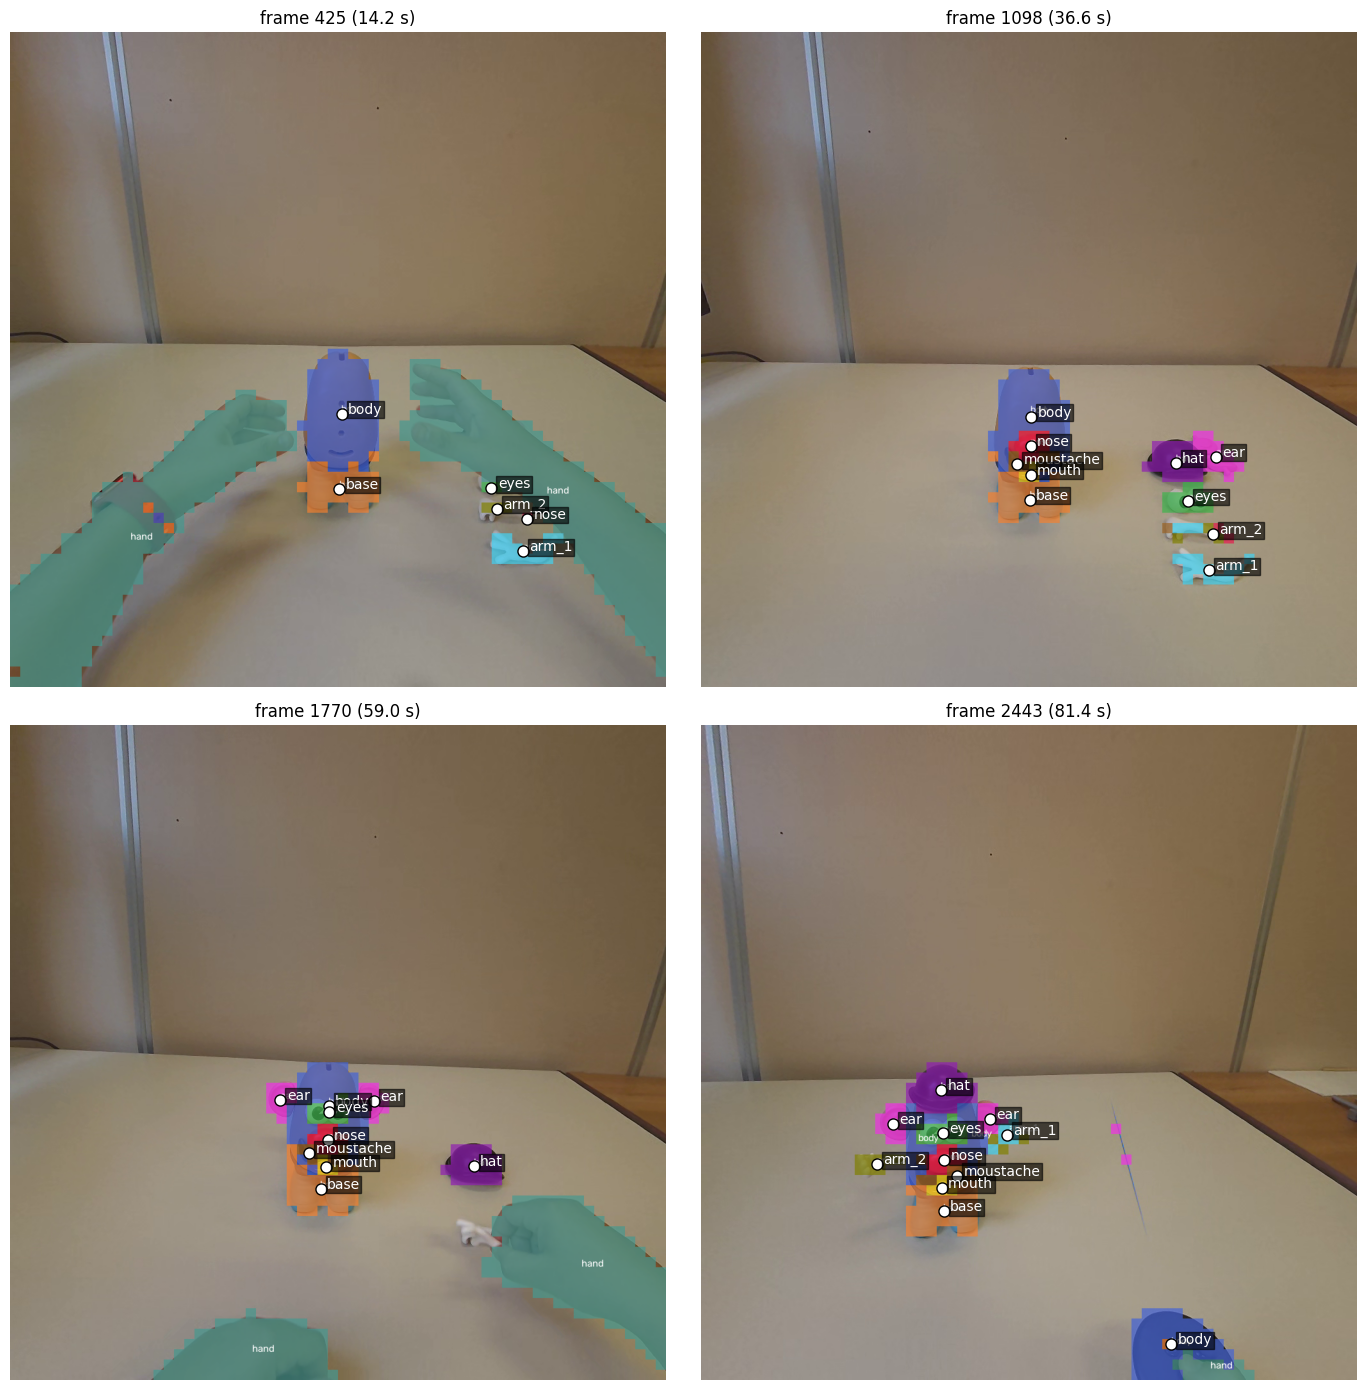

In [8]:
# 4.3 What the regions look like: labels on the frame, with the centre of every kept region
import matplotlib.pyplot as plt
from perception.visualization import render_overlay

SHOW_FRAMES = np.linspace(SETTLED["body"], N_FRAMES - 1, 4).round().astype(int)   # fixed rule, not chosen by looking
MIN_BLOB_PATCHES = 5            # smallest blob with a text label in the overlays, as in the pipeline

frames_rgb = {}
cap = cv2.VideoCapture(str(VIDEO_PATH))
for f in range(SHOW_FRAMES[-1] + 1):                          # read in order, as in Section 3
    ok, frame_bgr = cap.read()
    if f in SHOW_FRAMES:
        frames_rgb[f] = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
cap.release()

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for ax, f in zip(axes.ravel(), SHOW_FRAMES):
    ax.imshow(render_overlay(frames_rgb[f], LABELS[f], MIN_BLOB_PATCHES))
    for p in PARTS:
        for r in REGIONS[p][f]:
            x, y = (r["col"] + 0.5) * PATCH_SIZE, (r["row"] + 0.5) * PATCH_SIZE   # patch grid -> pixels
            ax.plot(x, y, "o", color="white", markeredgecolor="black", markersize=8)
            ax.text(x + 10, y, p, color="white", fontsize=10,
                    bbox=dict(facecolor="black", alpha=0.6, pad=1))
    ax.set_title(f"frame {f} ({f / FPS:.1f} s)")
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "regions_centres.png", dpi=100)
plt.show()

Observation 4.3: In the four frames (425, 1098, 1770 and 2443) the centres of the small, compact parts fall on the right parts: eyes, nose, mouth, arms and hat. At frame 1098 the two ears lie side by side on the table and form a single region, so only one ear has a centre. At frame 1098 the centre of the moustache is about one patch above the centre of the mouth.

The body is the problem. At frame 1770 its largest region is the upper part, cut by the face, so its centre is at the height of the eyes. At frame 2443 the largest body region is not on the figure: it is the controller of the headset, near the hand, labelled as body, and larger than what is left visible of the real body.

Hypothesis: the largest region works for small, compact parts but not for a part on which other parts are mounted, because its region splits and any larger false region wins. The controller shows the limit of Phase 1 that there is no answer "unknown". In the state tracking of Phase 2 a region is accepted only near the last known position of the part, which would discard the controller. Moustache and mouth are about one patch apart, so with no margin they can swap easily.

In [ ]:
# 4.4 Vertical relations in every frame where both parts are seen, with no margin
per_frame = []
for a, b in VERTICAL:
    start = max(SETTLED[a], SETTLED[b])
    for f in range(start, N_FRAMES):
        regions_a, regions_b = REGIONS[a][f], REGIONS[b][f]
        if not regions_a or not regions_b:
            continue                                   # one of the two parts is not seen: not checkable
        # positive distance = A is higher than B, as it should; for the ears the worst visible ear counts
        distance = min(rb["row"] - ra["row"] for ra in regions_a for rb in regions_b)
        per_frame.append({"relation": f"{a} above {b}", "frame": f, "distance": distance,
                          "violated": distance <= 0,
                          "hand": any(r["hand"] for r in regions_a + regions_b)})
PER_FRAME = pd.DataFrame(per_frame)
PER_FRAME.to_csv(OUTPUT_DIR / "vertical_relations_per_frame.csv", index=False)

rows = []
for a, b in VERTICAL:
    name = f"{a} above {b}"
    r = PER_FRAME[PER_FRAME["relation"] == name]
    with_hand, no_hand = r[r["hand"]], r[~r["hand"]]
    rows.append({"relation": name,
                 "frames to check": int(WINDOWS.loc[name, "frames to check"]),
                 "checkable": len(r),
                 "violated": int(r["violated"].sum()),
                 "violated (%)": round(100 * r["violated"].mean(), 1) if len(r) else None,
                 "hand: violated / frames": f"{int(with_hand['violated'].sum())} / {len(with_hand)}",
                 "no hand: violated / frames": f"{int(no_hand['violated'].sum())} / {len(no_hand)}",
                 "distance min": round(r["distance"].min(), 2),
                 "distance 5%": round(r["distance"].quantile(0.05), 2),
                 "distance median": round(r["distance"].median(), 2)})
VERTICAL_SUMMARY = pd.DataFrame(rows).set_index("relation")
display(VERTICAL_SUMMARY)